# Experiment 08 — Handling Class Imbalance with Resampling
**Credit Card Fraud Detection Under Extreme Class Imbalance**  
COSC 50303 Data Mining | Continuation of Experiment 07

**Research question:** Does changing the training class distribution improve fraud detection and reduce false alarms compared with standard and class-weighted Logistic Regression?

We compare five configurations of the same classifier: standard LR, weighted LR, random undersampling (RUS), random oversampling (ROS), and SMOTE. The three resampling methods use a fixed minority-to-majority ratio of 0.10 (1:10). This is a controlled comparison at one ratio, not a search for the best possible ratio. Thresholds are selected independently by maximizing validation F1 using the same procedure as Notebook 07.



**Evaluation note:** We reuse the earlier stratified 80/10/10 split for comparability. The test set has already been examined in previous experiments, so it is a reused held-out set, not a new independent test. Fix the configurations before evaluating it; do not choose sampling ratios or thresholds based on test results. A later development-only cross-validation study can assess stability. Follow your instructor's AI-use policy, acknowledge assistance if required, and write your own interpretation after running the experiment.

In [1]:
import sys
import json
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score,
    average_precision_score, precision_recall_curve,
    roc_auc_score, roc_curve, auc
)

try:
    import imblearn
    from imblearn.under_sampling import RandomUnderSampler
    from imblearn.over_sampling import RandomOverSampler, SMOTE
except ImportError as exc:
    raise ImportError("Install imbalanced-learn in fraud-mining and restart the kernel.") from exc

SEED = 42
SAMPLING_RATIO = 0.10
ALERT_BUDGET = 50
MAX_ITER = 1000

# Support running from either notebooks/ or the project root.
root = Path.cwd()
if not (root / "data/raw/creditcard.csv").is_file():
    root = root.parent
DATA_PATH = root / "data/raw/creditcard.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Cannot find data/raw/creditcard.csv. Open this notebook in the existing project.")

TABLE_DIR = root / "results/tables"
FIGURE_DIR = root / "results/figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("Dataset:", DATA_PATH)

Python: /Users/tankarajjoshi/anaconda3/envs/fraud-mining/bin/python3.11
scikit-learn: 1.9.1
imbalanced-learn: 0.14.2
Dataset: /Users/tankarajjoshi/Projects/credit-card-fraud-extreme-imbalance/data/raw/creditcard.csv


## 2. Load and clean the dataset
Follow Notebook 07: remove exact duplicate rows, retain all 30 features, and treat Class 1 as fraud. Identical rows are removed for consistency; without transaction identifiers, we cannot prove that all such rows were duplicate real-world events.

In [2]:
df = pd.read_csv(DATA_PATH)
expected_columns = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]
assert set(df.columns) == set(expected_columns), "Unexpected dataset columns."
assert not df.isna().any().any(), "Unexpected missing values; inspect before proceeding."
assert set(df["Class"].unique()) == {0, 1}, "Expected binary class labels 0 and 1."

df_clean = df.drop_duplicates().copy()
print("Original transactions:", len(df))
print("Duplicates removed:", len(df) - len(df_clean))
print("Cleaned transactions:", len(df_clean))
print(df_clean["Class"].value_counts().sort_index())

X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]

Original transactions: 284807
Duplicates removed: 1081
Cleaned transactions: 283726
Class
0    283253
1       473
Name: count, dtype: int64


## 3. Reproduce the split and standardize the features
Use the same two stratified splits as Notebook 07. Fit the scaler on the original training set only, before resampling. Validation and test retain their real class distribution and are never resampled.

In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

split_summary = pd.DataFrame([
    {"Split": name, "Total": len(labels), "Normal": int((labels == 0).sum()),
     "Fraud": int((labels == 1).sum()), "Fraud %": 100 * labels.mean()}
    for name, labels in [("Training", y_train), ("Validation", y_val), ("Test", y_test)]
]).set_index("Split")
display(split_summary.round(4))

expected = [(226980, 378), (28373, 48), (28373, 47)]
actual = [(len(labels), int(labels.sum())) for labels in [y_train, y_val, y_test]]
if actual != expected:
    print("WARNING: Split counts differ from Notebook 07. Verify dataset before comparing results.")
else:
    print("Split counts match Notebook 07.")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

,Total,Normal,Fraud,Fraud %
Split,,,,
Training,226980,226602,378,0.1665
Validation,28373,28325,48,0.1692
Test,28373,28326,47,0.1657


Split counts match Notebook 07.


## 4. Define five model configurations
- **Standard LR:** original training data, equal class weights.
- **Weighted LR:** original data, `class_weight="balanced"`.
- **RUS + LR:** randomly removes majority-class observations, keeping all minority observations.
- **ROS + LR:** randomly repeats minority observations, preserving the majority class.
- **SMOTE + LR:** creates synthetic minority examples between neighboring minority observations (`k_neighbors=5`).

The ratio 0.10 means minority count / majority count after resampling, not 10% of the total. For our original training counts (226,602 normal and 378 fraud), RUS targets 3,780 normal / 378 fraud; ROS and SMOTE target 226,602 normal / 22,660 fraud. Synthetic or repeated observations are not additional independently observed fraud cases. No class weighting is combined with resampling in this experiment, so each technique is isolated.

In [7]:
configurations = [
    ("Standard LR", None, None),
    ("Weighted LR", None, "balanced"),
    ("RUS + LR", RandomUnderSampler(sampling_strategy=SAMPLING_RATIO, random_state=SEED), None),
    ("ROS + LR", RandomOverSampler(sampling_strategy=SAMPLING_RATIO, random_state=SEED), None),
    ("SMOTE + LR", SMOTE(sampling_strategy=SAMPLING_RATIO, random_state=SEED, k_neighbors=5), None)
]

models = {}
training_rows = []
val_scores = {}

for name, sampler, class_weight in configurations:
    start = perf_counter()
    if sampler is None:
        X_fit, y_fit = X_train_scaled, y_train
    else:
        X_fit, y_fit = sampler.fit_resample(X_train_scaled, y_train)
    sampling_seconds = perf_counter() - start

    model = LogisticRegression(max_iter=MAX_ITER, random_state=SEED,
                               class_weight=class_weight)
    start = perf_counter()
    model.fit(X_fit, y_fit)
    fit_seconds = perf_counter() - start

    normal = int((y_fit == 0).sum())
    fraud = int((y_fit == 1).sum())
    training_rows.append({
        "Model": name, "Normal": normal, "Fraud": fraud,
        "Total": normal + fraud, "Fraud/Normal": fraud / normal,
        "Sampling seconds": sampling_seconds, "Fit seconds": fit_seconds,
        "Iterations": int(model.n_iter_[0])
    })
    models[name] = model
    val_scores[name] = model.predict_proba(X_val_scaled)[:, 1]
    print(f"{name}: trained on {normal:,} normal and {fraud:,} fraud samples")

training_summary = pd.DataFrame(training_rows).set_index("Model")
display(training_summary.round(4))

Standard LR: trained on 226,602 normal and 378 fraud samples
Weighted LR: trained on 226,602 normal and 378 fraud samples
RUS + LR: trained on 3,780 normal and 378 fraud samples
ROS + LR: trained on 226,602 normal and 22,660 fraud samples
SMOTE + LR: trained on 226,602 normal and 22,660 fraud samples


,Normal,Fraud,Total,Fraud/Normal,Sampling seconds,Fit seconds,Iterations
Model,,,,,,,
Standard LR,226602,378,226980,0.0017,0.0018,0.1833,14
Weighted LR,226602,378,226980,0.0017,0.0000,0.5527,37
RUS + LR,3780,378,4158,0.1000,0.0188,0.0049,29
ROS + LR,226602,22660,249262,0.1000,0.0373,0.3408,28
SMOTE + LR,226602,22660,249262,0.1000,0.0346,0.3232,26


## 5. Select thresholds using validation data only
Use the same method as Notebook 07: evaluate all distinct validation scores via the precision-recall curve, choose the candidate with maximum F1, and break exact ties by the first (lowest) threshold. Keep the full numerical precision of each threshold. Weighted and resampled model scores are not necessarily calibrated real-world fraud probabilities.

Average Precision (AP) and trapezoidal PR-AUC are related but not identical; report them separately. ROC-AUC is a supporting metric. Alert burden is the number of transactions flagged (`TP + FP`). Also compare at a fixed 50-alert budget: rank by score and take the top 50, breaking score ties by original split order, never by the true labels. This budget is an illustrative fixed workload, not a claim about a bank's actual staffing capacity.

In [8]:
def find_best_threshold(y_true, probabilities):
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    precision = precision[:-1]
    recall = recall[:-1]
    f1 = 2 * precision * recall / (precision + recall + 1e-10)
    return float(thresholds[np.argmax(f1)])


def evaluate_model(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    (tp, fn), (fp, tn) = confusion_matrix(y_true, predictions, labels=[1, 0])
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    return {
        "Threshold": threshold,
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "AP": average_precision_score(y_true, probabilities),
        "PR-AUC": auc(recall, precision),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "Alerts": int(tp + fp),
        "Alerts per 1000": 1000 * (tp + fp) / len(y_true)
    }


def evaluate_alert_budget(y_true, probabilities, budget=ALERT_BUDGET):
    labels = np.asarray(y_true)
    k = min(budget, len(labels))
    top = np.argsort(-probabilities, kind="stable")[:k]
    tp = int(labels[top].sum())
    return {
        "Alert budget": k,
        "Fraud detected": tp,
        "False alarms": k - tp,
        "Precision@50": tp / k,
        "Recall@50": tp / labels.sum()
    }

thresholds = {name: find_best_threshold(y_val, scores)
              for name, scores in val_scores.items()}
validation_results = pd.DataFrame.from_dict({
    name: evaluate_model(y_val, scores, thresholds[name])
    for name, scores in val_scores.items()
}, orient="index")
validation_results.index.name = "Model"

display(validation_results.round(6))
print("Highest validation F1:", validation_results["F1"].idxmax())
print("Highest validation AP:", validation_results["AP"].idxmax())

,Threshold,TP,FN,FP,TN,Precision,Recall,F1,AP,PR-AUC,ROC-AUC,Alerts,Alerts per 1000
Model,,,,,,,,,,,,,
Standard LR,0.088505,34,14,6,28319,0.850000,0.708333,0.772727,0.644898,0.641920,0.932161,40,1.409791
Weighted LR,0.999991,35,13,5,28320,0.875000,0.729167,0.795455,0.647771,0.672527,0.947106,40,1.409791
RUS + LR,0.999999,34,14,4,28321,0.894737,0.708333,0.790698,0.632771,0.655473,0.942190,38,1.339301
ROS + LR,0.904612,36,12,7,28318,0.837209,0.750000,0.791209,0.655586,0.652135,0.951320,43,1.515525
SMOTE + LR,0.900304,36,12,6,28319,0.857143,0.750000,0.800000,0.658343,0.655019,0.948539,42,1.480281


Highest validation F1: SMOTE + LR
Highest validation AP: SMOTE + LR


## 6. Held-out test comparison
The configurations and validation thresholds are now fixed. Use the same test samples for every model. Do not revise the ratio or thresholds based on the following table. The results are descriptive for this reused test split; small differences on 47 fraud cases are not proof of a general improvement.

In [9]:
test_scores = {name: model.predict_proba(X_test_scaled)[:, 1]
               for name, model in models.items()}

test_results = pd.DataFrame.from_dict({
    name: evaluate_model(y_test, scores, thresholds[name])
    for name, scores in test_scores.items()
}, orient="index")
test_results.index.name = "Model"

alert_results = pd.DataFrame.from_dict({
    name: evaluate_alert_budget(y_test, scores)
    for name, scores in test_scores.items()
}, orient="index")
alert_results.index.name = "Model"

print("Test results at validation-selected thresholds:")
display(test_results.round(6))
print("Test comparison at the same 50-alert budget:")
display(alert_results.round(6))

# Check confusion-matrix totals and unchanged validation thresholds.
assert (test_results[["TP", "FN", "FP", "TN"]].sum(axis=1) == len(y_test)).all()
assert (test_results["TP"] + test_results["FN"] == y_test.sum()).all()
assert np.array_equal(test_results["Threshold"].to_numpy(), validation_results["Threshold"].to_numpy())

Test results at validation-selected thresholds:


,Threshold,TP,FN,FP,TN,Precision,Recall,F1,AP,PR-AUC,ROC-AUC,Alerts,Alerts per 1000
Model,,,,,,,,,,,,,
Standard LR,0.088505,37,10,9,28317,0.804348,0.787234,0.795699,0.744728,0.742109,0.980660,46,1.621260
Weighted LR,0.999991,38,9,8,28318,0.826087,0.808511,0.817204,0.699136,0.738610,0.984731,46,1.621260
RUS + LR,0.999999,37,10,6,28320,0.860465,0.787234,0.822222,0.673445,0.707635,0.983659,43,1.515525
ROS + LR,0.904612,39,8,12,28314,0.764706,0.829787,0.795918,0.731536,0.727735,0.983998,51,1.797484
SMOTE + LR,0.900304,38,9,11,28315,0.775510,0.808511,0.791667,0.729487,0.725683,0.984916,49,1.726994


Test comparison at the same 50-alert budget:


,Alert budget,Fraud detected,False alarms,Precision@50,Recall@50
Model,,,,,
Standard LR,50,39,11,0.78,0.829787
Weighted LR,50,38,12,0.76,0.808511
RUS + LR,50,38,12,0.76,0.808511
ROS + LR,50,38,12,0.76,0.808511
SMOTE + LR,50,39,11,0.78,0.829787


## 7. Plot training distributions and final metrics
Figures are saved from their specific figure objects before `plt.show()` to avoid blank images. Counts use a logarithmic scale because the original imbalance is extreme.

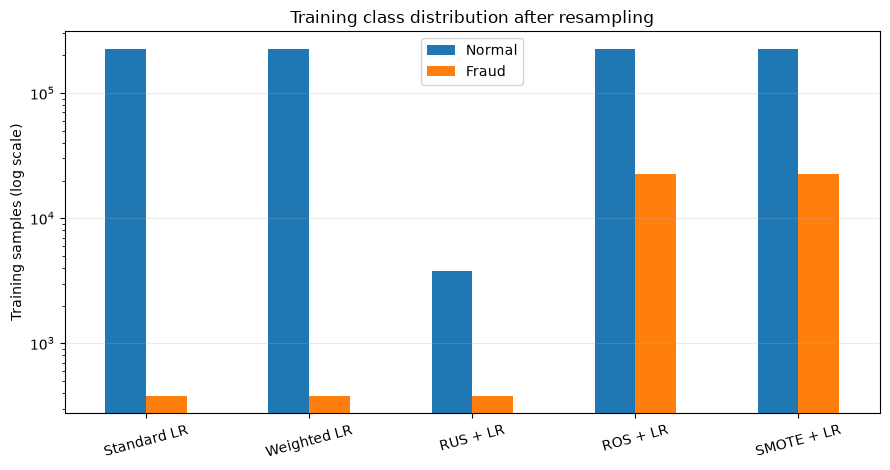

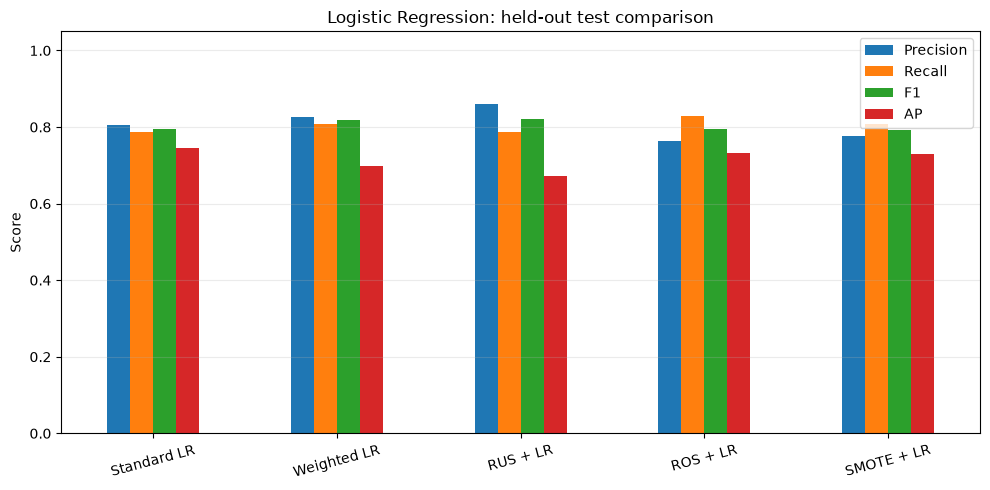

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.8))
training_summary[["Normal", "Fraud"]].plot.bar(ax=ax, logy=True, rot=15)
ax.set_title("Training class distribution after resampling")
ax.set_ylabel("Training samples (log scale)")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_training_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
test_results[["Precision", "Recall", "F1", "AP"]].plot.bar(ax=ax, rot=15)
ax.set_title("Logistic Regression: held-out test comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_lr_metric_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. Confusion matrices
Fraud is listed first in both rows and columns. Rows are actual classes; columns are predictions. Compare fraud detected (TP), fraud missed (FN), and false alarms (FP), not just the very large number of correctly classified normal transactions.

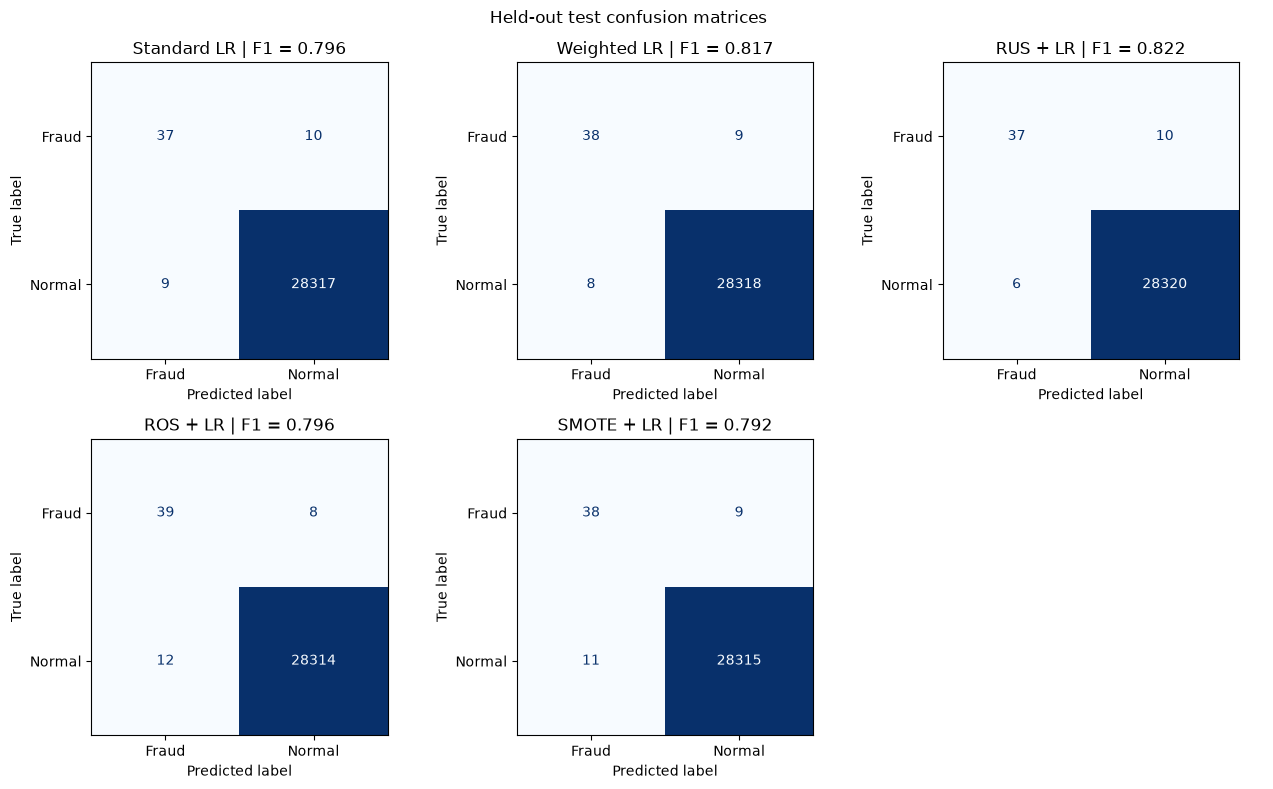

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, (name, scores) in zip(axes.flat, test_scores.items()):
    predictions = (scores >= thresholds[name]).astype(int)
    cm = confusion_matrix(y_test, predictions, labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["Fraud", "Normal"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(f"{name} | F1 = {test_results.loc[name, 'F1']:.3f}")
axes.flat[-1].axis("off")
fig.suptitle("Held-out test confusion matrices")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_lr_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Precision-recall and ROC curves
The PR plot is especially useful when fraud is rare. Its horizontal baseline equals the fraction of actual fraud cases in the test data. The ROC plot provides complementary ranking information. AP and ROC-AUC do not depend on the selected operating threshold.

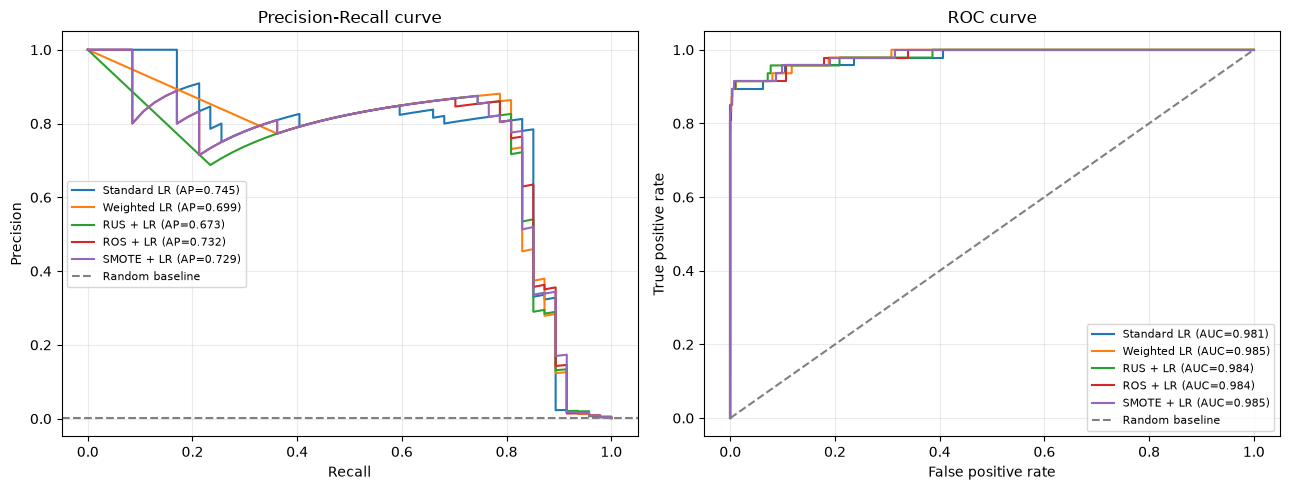

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    axes[0].plot(recall, precision, label=f"{name} (AP={test_results.loc[name, 'AP']:.3f})")
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={test_results.loc[name, 'ROC-AUC']:.3f})")

axes[0].axhline(y_test.mean(), linestyle="--", color="gray", label="Random baseline")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Random baseline")
axes[0].set(title="Precision-Recall curve", xlabel="Recall", ylabel="Precision")
axes[1].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "08_lr_pr_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Save results and reproducibility settings
Save only aggregate metrics, plots and experiment settings. No raw transactions, row-level predictions, resampled datasets or trained models are written. Filenames are unique to Experiment 08; existing Experiment 07 results are not overwritten.

In [13]:
for filename, table in {
    "08_split_summary.csv": split_summary,
    "08_lr_training_summary.csv": training_summary,
    "08_lr_validation_comparison.csv": validation_results,
    "08_lr_test_comparison.csv": test_results,
    "08_lr_alert_budget.csv": alert_results
}.items():
    table.to_csv(TABLE_DIR / filename, float_format="%.17g")

settings = {
    "seed": SEED, "split": [0.8, 0.1, 0.1],
    "remove_exact_duplicates": True, "scaling": "StandardScaler fitted on original train only",
    "sampling_strategy": SAMPLING_RATIO, "smote_k_neighbors": 5,
    "threshold_selection": "Maximum validation F1; lowest threshold for exact ties",
    "alert_budget": ALERT_BUDGET, "max_iter": MAX_ITER,
    "model_parameters": {name: model.get_params() for name, model in models.items()},
    "selected_thresholds": thresholds,
    "versions": {"python": sys.version.split()[0], "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
                 "imbalanced-learn": imblearn.__version__}
}
(TABLE_DIR / "08_lr_experiment_config.json").write_text(json.dumps(settings, indent=2))

print("Saved Experiment 08 files:")
for folder in [TABLE_DIR, FIGURE_DIR]:
    for path in sorted(folder.glob("08_*")):
        print(path.relative_to(root), f"({path.stat().st_size:,} bytes)")

Saved Experiment 08 files:
results/tables/08_lr_alert_budget.csv (368 bytes)
results/tables/08_lr_experiment_config.json (2,585 bytes)
results/tables/08_lr_test_comparison.csv (1,016 bytes)
results/tables/08_lr_training_summary.csv (552 bytes)
results/tables/08_lr_validation_comparison.csv (973 bytes)
results/tables/08_split_summary.csv (166 bytes)
results/figures/08_lr_confusion_matrices.png (216,661 bytes)
results/figures/08_lr_metric_comparison.png (95,559 bytes)
results/figures/08_lr_pr_roc_curves.png (275,776 bytes)
results/figures/08_training_distribution.png (89,979 bytes)


## Experiment 08: Conclusion

In this experiment, I compared five Logistic Regression
configurations using the same data split and evaluation
procedure.

Random Undersampling achieved the highest test F1-score
of 82.22% and reduced false alarms from 9 to 6 compared
with Standard Logistic Regression.

Random Oversampling detected the highest number of fraud
cases but generated more false alarms. SMOTE achieved
the highest validation F1-score, but this improvement
did not carry over to the test set.

Standard Logistic Regression achieved the highest test
Average Precision of 0.7447.

Under the same 50-alert budget, Standard Logistic
Regression and SMOTE both detected 39 fraud cases.

These results suggest that imbalance-handling techniques
do not necessarily improve every performance metric.
Further cross-validation is needed to examine the
stability of these findings.